# Лабораторная работа № 3. Оптимизация гиперпараметров SVM

**Цель.** Сравнить полный и случайный поиск гиперпараметров SVM с RBF-ядром на задаче классификации пассажиров Titanic. Измерить F1 для выживших (`Survived=1`), оценить разброс по фолдам и влияние настроек на качество. [Задание](https://github.com/lesopylka/ml_course_mai/blob/main/hyperparameters/lab03.pdf).

## 1. Исходные данные

Используется [Titanic Dataset](https://www.kaggle.com/datasets/yasserh/titanic-dataset), CC0. Проверены пропуски и распределение целевой переменной.

In [1]:
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import loguniform
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.model_selection import (GridSearchCV, RandomizedSearchCV,
                                     StratifiedKFold, cross_validate, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC

RANDOM_STATE = 2026
pd.set_option('display.precision', 4)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.2})

data = pd.read_csv(Path('../data/Titanic-Dataset.csv'))
assert data.shape == (891, 12)
assert set(data['Survived']) == {0, 1}
display(data.head())
display(pd.DataFrame({'пропусков': data.isna().sum(),
                      'доля пропусков': data.isna().mean()}).sort_values('пропусков', ascending=False))
print('доли классов:', data['Survived'].value_counts(normalize=True).sort_index().round(3).to_dict())

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


,пропусков,доля пропусков
Cabin,687,0.7710
Age,177,0.1987
Embarked,2,0.0022
PassengerId,0,0.0000
Name,0,0.0000
Pclass,0,0.0000
Survived,0,0.0000
Sex,0,0.0000
Parch,0,0.0000
SibSp,0,0.0000


доли классов: {0: 0.616, 1: 0.384}


Из исходной таблицы используются семь признаков: `Pclass`, `Sex`, `Age`, `SibSp`, `Parch`, `Fare` и `Embarked`.

## 2. Протокол оценки

Используется стратифицированное разбиение `random_state=2026` на 712 обучающих и 179 тестовых записей. Пять общих стратифицированных фолдов позволяют оценить разброс и уменьшают зависимость от состава одной валидационной части. Выбор настроек проводится по среднему F1 на фолдах обучающей выборки. Сравнение кандидатов по тестовой метрике сделало бы оценку оптимистичной.

In [2]:
FEATURES = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']
X = data[FEATURES].copy()
y = data['Survived'].copy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE,
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print('train:', len(X_train), 'test:', len(X_test))
display(pd.DataFrame({'train': y_train.value_counts(normalize=True),
                      'test': y_test.value_counts(normalize=True)}).sort_index())
assert set(X_train.index).isdisjoint(X_test.index)

train: 712 test: 179


,train,test
Survived,,
0,0.6166,0.6145
1,0.3834,0.3855


## 3. Предобработка

Числовые пропуски заполняются медианой, категориальные — модой. Числовые признаки стандартизуются, категориальные кодируются индикаторами. Конвейер оценивает параметры преобразований отдельно на обучающей части каждого фолда.

In [3]:
numeric_features = ['Age', 'SibSp', 'Parch', 'Fare']
categorical_features = ['Pclass', 'Sex', 'Embarked']

def make_model(estimator):
    preprocess = ColumnTransformer([
        ('num', Pipeline([
            ('fill', SimpleImputer(strategy='median')),
            ('scale', StandardScaler()),
        ]), numeric_features),
        ('cat', Pipeline([
            ('fill', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
        ]), categorical_features),
    ])
    return Pipeline([('preprocess', preprocess), ('model', estimator)])

## 4. Пространство гиперпараметров

| Гиперпараметр | Роль и ожидаемый эффект | Значения Grid Search | Пространство Random Search |
|---|---|---|---|
| `C` | Регулирует штраф за нарушения зазора. Большие значения могут увеличивать риск переобучения. | 0.1, 1, 10, 100 | `loguniform(0.05, 100)` |
| `gamma` | Определяет скорость убывания похожести в RBF-ядре. Большие значения делают влияние объектов более локальным. | 0.001, 0.01, 0.1, 1 | `loguniform(0.001, 1)` |
| `class_weight` | Меняет относительный вес классов; `balanced` повышает вес менее частого класса. | `None`, `balanced` | те же варианты |

Логарифмическая шкала охватывает несколько порядков величины при равном внимании к каждому диапазону в десять раз.

## 5. Исходная модель

Базовая конфигурация из лабораторной № 2: `C=1`, `gamma=0.1`, `class_weight=None`. Метрики пересчитаны на разбиении текущей работы.

In [4]:
baseline_model = make_model(SVC(kernel='rbf', C=1, gamma=0.1, class_weight=None))
baseline_cv = cross_validate(
    baseline_model, X_train, y_train, cv=cv, scoring='f1',
    return_train_score=True, n_jobs=1,
)
baseline_model.fit(X_train, y_train)
print('параметры baseline: C=1, gamma=0.1, class_weight=None, kernel=rbf')
print('cv f1:', round(baseline_cv['test_score'].mean(), 4),
      '+/-', round(baseline_cv['test_score'].std(), 4))
print('f1 по фолдам:', np.round(baseline_cv['test_score'], 4))

параметры baseline: C=1, gamma=0.1, class_weight=None, kernel=rbf
cv f1: 0.7458 +/- 0.0338
f1 по фолдам: [0.6923 0.75   0.78   0.7255 0.781 ]


Исходный средний CV F1 составил **0,7458**, стандартное отклонение — 0,0338.

## 6. Grid Search

Выполнен полный перебор 32 комбинаций с пятью фолдами на комбинацию.

In [5]:
grid_params = {
    'model__C': [0.1, 1, 10, 100],
    'model__gamma': [0.001, 0.01, 0.1, 1],
    'model__class_weight': [None, 'balanced'],
}
grid_search = GridSearchCV(
    make_model(SVC(kernel='rbf')), grid_params, cv=cv, scoring='f1',
    n_jobs=1, return_train_score=True, refit=True,
)
start = perf_counter()
grid_search.fit(X_train, y_train)
grid_seconds = perf_counter() - start
print('проверено комбинаций:', len(grid_search.cv_results_['params']))
print('лучшие параметры:', grid_search.best_params_)
print('лучший cv f1:', round(grid_search.best_score_, 4))
print('время, с:', round(grid_seconds, 2))

проверено комбинаций: 32
лучшие параметры: {'model__C': 1, 'model__class_weight': None, 'model__gamma': 0.1}
лучший cv f1: 0.7458
время, с: 17.25


Grid Search вернул параметры базовой конфигурации. Средний CV F1 — **0,7458**.

## 7. Random Search

Выполнено 32 случайных пробы на тех же фолдах. Непрерывные диапазоны позволяют проверить значения между точками сетки.

In [6]:
random_params = {
    'model__C': loguniform(0.05, 100),
    'model__gamma': loguniform(0.001, 1),
    'model__class_weight': [None, 'balanced'],
}
random_search = RandomizedSearchCV(
    make_model(SVC(kernel='rbf')), random_params, n_iter=32,
    cv=cv, scoring='f1', n_jobs=1, random_state=RANDOM_STATE,
    return_train_score=True, refit=True,
)
start = perf_counter()
random_search.fit(X_train, y_train)
random_seconds = perf_counter() - start
print('проверено комбинаций:', len(random_search.cv_results_['params']))
print('лучшие параметры: C=', round(float(random_search.best_params_['model__C']), 4),
      'gamma=', round(float(random_search.best_params_['model__gamma']), 4),
      'class_weight=', random_search.best_params_['model__class_weight'])
print('лучший cv f1:', round(random_search.best_score_, 4))
print('время, с:', round(random_seconds, 2))

проверено комбинаций: 32
лучшие параметры: C= 0.4983 gamma= 0.108 class_weight= balanced
лучший cv f1: 0.7473
время, с: 16.31


Выбраны `C≈0.4983`, `gamma≈0.1080`, `class_weight=balanced`. Средний CV F1 — **0,7473**.

## 8. Сравнение качества и времени поиска

Бюджет каждого поиска — 160 обучений на фолдах и одно финальное обучение победителя на полном train. Модель выбирается по среднему CV F1.

In [7]:
search_table = pd.DataFrame([
    {'метод': 'baseline', 'комбинаций': 1,
     'cv f1': baseline_cv['test_score'].mean(),
     'разброс cv': baseline_cv['test_score'].std(), 'время поиска, с': np.nan},
    {'метод': 'grid', 'комбинаций': len(grid_search.cv_results_['params']),
     'cv f1': grid_search.best_score_,
     'разброс cv': grid_search.cv_results_['std_test_score'][grid_search.best_index_],
     'время поиска, с': grid_seconds},
    {'метод': 'random', 'комбинаций': len(random_search.cv_results_['params']),
     'cv f1': random_search.best_score_,
     'разброс cv': random_search.cv_results_['std_test_score'][random_search.best_index_],
     'время поиска, с': random_seconds},
]).set_index('метод')
display(search_table)
chosen_name = 'grid' if grid_search.best_score_ >= random_search.best_score_ else 'random'
print('по train-cv выбран:', chosen_name)

,комбинаций,cv f1,разброс cv,"время поиска, с"
метод,,,,
baseline,1,0.7458,0.0338,NaN
grid,32,0.7458,0.0338,17.2507
random,32,0.7473,0.0274,16.3107


по train-cv выбран: random


На графике показан лучший найденный CV F1 по мере перебора комбинаций.

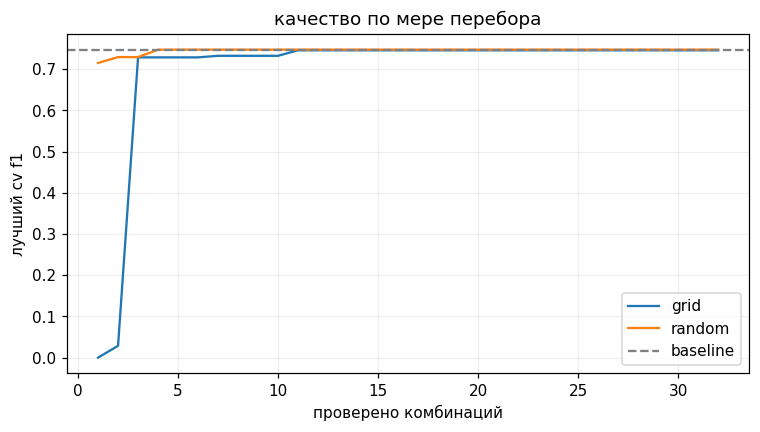

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
for label, search in [('grid', grid_search), ('random', random_search)]:
    scores = np.asarray(search.cv_results_['mean_test_score'])
    ax.plot(np.arange(1, len(scores) + 1), np.maximum.accumulate(scores),
            label=label)
ax.axhline(baseline_cv['test_score'].mean(), color='gray', ls='--', label='baseline')
ax.set(xlabel='проверено комбинаций', ylabel='лучший cv f1',
       title='качество по мере перебора')
ax.legend()
plt.show()

## 9. Влияние гиперпараметров

Тепловые карты показывают CV F1 для пар `C` и `gamma` при двух вариантах весов. Значения ниже нижней границы цветовой шкалы можно сравнить по подписям в ячейках.

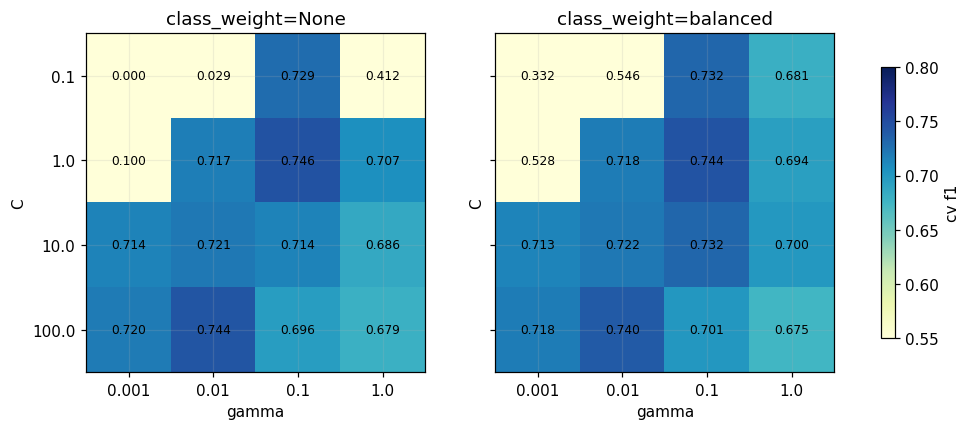

,mean,max
веса,,
None,0.5696,0.7458
balanced,0.6674,0.7445


In [9]:
grid_results = pd.DataFrame(grid_search.cv_results_)
grid_results['C'] = grid_results['param_model__C'].astype(float)
grid_results['gamma'] = grid_results['param_model__gamma'].astype(float)
grid_results['веса'] = grid_results['param_model__class_weight'].map(
    lambda value: 'balanced' if value == 'balanced' else 'None'
)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, label in zip(axes, ['None', 'balanced']):
    part = grid_results[grid_results['веса'] == label]
    values = part.pivot(index='C', columns='gamma', values='mean_test_score')
    image = ax.imshow(values.to_numpy(), vmin=0.55, vmax=0.80, cmap='YlGnBu')
    ax.set_xticks(range(len(values.columns)), [str(v) for v in values.columns])
    ax.set_yticks(range(len(values.index)), [str(v) for v in values.index])
    ax.set(xlabel='gamma', ylabel='C', title=f'class_weight={label}')
    for row in range(values.shape[0]):
        for col in range(values.shape[1]):
            ax.text(col, row, f'{values.iloc[row, col]:.3f}',
                    ha='center', va='center', fontsize=8)
fig.colorbar(image, ax=axes, shrink=0.8, label='cv f1')
plt.show()
display(grid_results.groupby('веса')['mean_test_score'].agg(['mean', 'max']))

Наибольший CV F1 сетки получен при `C=1`, `gamma=0.1` и `class_weight=None`. Сбалансированные веса улучшили некоторые конфигурации, а наилучшая точка оказалась без них.

Далее `gamma=0.1` и `class_weight=None` фиксируются, а F1 сравнивается на обучающих и валидационных частях фолдов при изменении `C`.

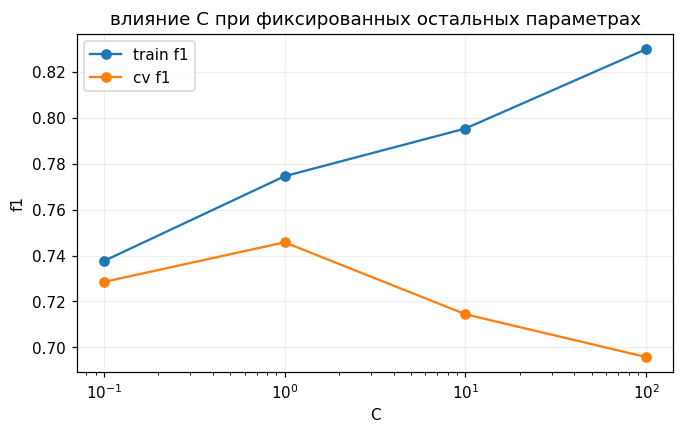

,C,mean_train_score,mean_test_score
2,0.1,0.7376,0.7285
10,1.0,0.7745,0.7458
18,10.0,0.7953,0.7144
26,100.0,0.8298,0.6958


In [10]:
best = grid_search.best_params_
selected = grid_results[
    np.isclose(grid_results['gamma'], best['model__gamma'])
    & (grid_results['веса'] == ('balanced' if best['model__class_weight'] == 'balanced' else 'None'))
].sort_values('C')
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(selected['C'], selected['mean_train_score'], marker='o', label='train f1')
ax.plot(selected['C'], selected['mean_test_score'], marker='o', label='cv f1')
ax.set_xscale('log')
ax.set(xlabel='C', ylabel='f1', title='влияние C при фиксированных остальных параметрах')
ax.legend()
plt.show()
display(selected[['C', 'mean_train_score', 'mean_test_score']])

При увеличении `C` с 0.1 до 1 CV F1 вырос с 0,7285 до 0,7458. При `C=100` CV F1 снизился до 0,6958, несмотря на рост обучающей метрики. Это указывает на переобучение в данном срезе.

## 10. Разброс по фолдам

Для каждой модели приведены пять значений F1, среднее, стандартное отклонение и диапазон.

In [11]:
fold_rows = []
for label, scores in [
    ('baseline', baseline_cv['test_score']),
    ('grid', [grid_search.cv_results_[f'split{i}_test_score'][grid_search.best_index_]
              for i in range(5)]),
    ('random', [random_search.cv_results_[f'split{i}_test_score'][random_search.best_index_]
                for i in range(5)]),
]:
    scores = np.asarray(scores, dtype=float)
    fold_rows.append({'метод': label, **{f'fold {i+1}': score for i, score in enumerate(scores)},
                      'среднее': scores.mean(), 'std': scores.std(),
                      'min': scores.min(), 'max': scores.max()})
fold_table = pd.DataFrame(fold_rows).set_index('метод')
display(fold_table)

,fold 1,fold 2,fold 3,fold 4,fold 5,среднее,std,min,max
метод,,,,,,,,,
baseline,0.6923,0.7500,0.7800,0.7255,0.7810,0.7458,0.0338,0.6923,0.7810
grid,0.6923,0.7500,0.7800,0.7255,0.7810,0.7458,0.0338,0.6923,0.7810
random,0.7103,0.7636,0.7778,0.7184,0.7664,0.7473,0.0274,0.7103,0.7778


## 11. Оценка на тестовой выборке

Базовая модель и выбранные конфигурации обоих поисков сравниваются на одном отложенном тесте.

In [12]:
models = {
    'baseline': baseline_model,
    'grid': grid_search.best_estimator_,
    'random': random_search.best_estimator_,
}
test_rows = []
for label, model in models.items():
    predicted = model.predict(X_test)
    test_rows.append({
        'метод': label,
        'cv f1': search_table.loc[label, 'cv f1'],
        'test f1': f1_score(y_test, predicted),
        'accuracy': accuracy_score(y_test, predicted),
        'precision': precision_score(y_test, predicted, zero_division=0),
        'recall': recall_score(y_test, predicted, zero_division=0),
    })
test_table = pd.DataFrame(test_rows).set_index('метод')
test_table['разница test f1 с baseline'] = test_table['test f1'] - test_table.loc['baseline', 'test f1']
display(test_table)
print('модель, выбранная по train-cv:', chosen_name)
print('её test f1:', round(test_table.loc[chosen_name, 'test f1'], 4))

,cv f1,test f1,accuracy,precision,recall,разница test f1 с baseline
метод,,,,,,
baseline,0.7458,0.7597,0.8268,0.8167,0.7101,0.0000
grid,0.7458,0.7597,0.8268,0.8167,0.7101,0.0000
random,0.7473,0.7538,0.8212,0.8033,0.7101,-0.0058


модель, выбранная по train-cv: random
её test f1: 0.7538


## Выводы

Лучший CV F1 показал Random Search (0,7473 против 0,7458 у baseline и Grid Search). На отложенной локальной выборке преимущество не подтвердилось: **0,7538 против 0,7597**. Разброс F1 по фолдам составляет 0,0274 для Random Search и 0,0338 для двух других вариантов; результаты характеризуют одно разбиение и небольшой набор настроек. Время выполнения зависит от оборудования.